In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




In [ ]:
from google.colab import files

uploaded = files.upload()

Saving TEMP_ANNUAL_SEASONAL_MEAN.csv to TEMP_ANNUAL_SEASONAL_MEAN (3).csv


In [ ]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (123, 6)


,YEAR,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,1901.0,25.42,20.11,27.64,28.16,23.1
1,1902.0,25.42,20.88,27.96,27.98,22.51
2,1903.0,25.01,19.99,27.02,28,22.33
3,1904.0,24.93,19.76,27.23,27.57,22.56
4,1905.0,24.84,18.36,26.38,28.2,23.13


In [ ]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna(how='all')
    df = df.dropna(subset=['YEAR'])
    df = df.dropna()
    df = df.reset_index(drop=True)
    print("Data Cleaning Completed!")
    print("Dataset Shape:", df.shape)
    print(df.isnull().sum())

Data Cleaning Completed!
Dataset Shape: (121, 6)
YEAR       0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64
Data Cleaning Completed!
Dataset Shape: (121, 6)
YEAR       0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64
Data Cleaning Completed!
Dataset Shape: (121, 6)
YEAR       0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64
Data Cleaning Completed!
Dataset Shape: (121, 6)
YEAR       0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64
Data Cleaning Completed!
Dataset Shape: (121, 6)
YEAR       0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64
Data Cleaning Completed!
Dataset Shape: (121, 6)
YEAR       0
ANNUAL     0
JAN-FEB    0
MAR-MAY    0
JUN-SEP    0
OCT-DEC    0
dtype: int64


In [ ]:

df = df.sort_values('YEAR').reset_index(drop=True)


temperature_columns = [
    'ANNUAL',
    'JAN-FEB',
    'MAR-MAY',
    'JUN-SEP',
    'OCT-DEC'
]


print("Research Dataset")
print("----------------")
print("Start Year:", int(df['YEAR'].min()))
print("End Year:", int(df['YEAR'].max()))
print("Total Years:", len(df))

print("\nTemperature Variables:")
print(temperature_columns)

print("\nDataset Preview:")
display(df.head())

Research Dataset
----------------
Start Year: 1901
End Year: 2021
Total Years: 121

Temperature Variables:
['ANNUAL', 'JAN-FEB', 'MAR-MAY', 'JUN-SEP', 'OCT-DEC']

Dataset Preview:


,YEAR,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
0,1901.0,25.42,20.11,27.64,28.16,23.10
1,1902.0,25.42,20.88,27.96,27.98,22.51
2,1903.0,25.01,19.99,27.02,28.00,22.33
3,1904.0,24.93,19.76,27.23,27.57,22.56
4,1905.0,24.84,18.36,26.38,28.20,23.13


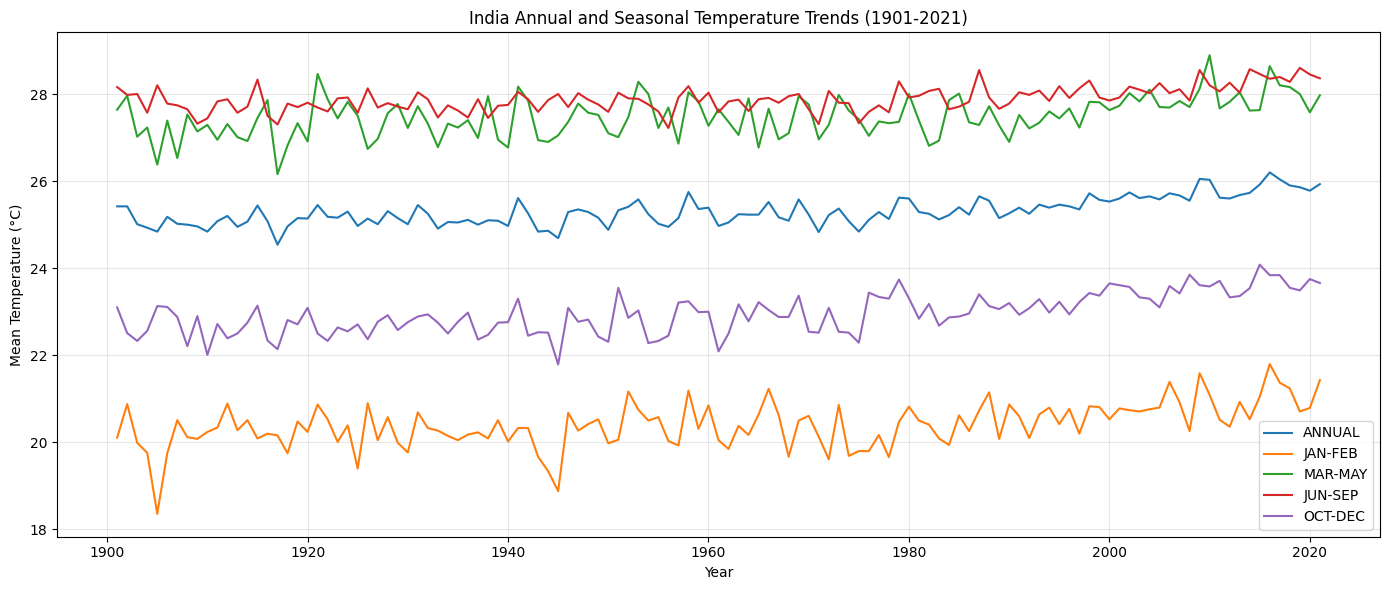

In [ ]:
plt.figure(figsize=(14, 6))

for col in temperature_columns:
    plt.plot(df['YEAR'], df[col], label=col)

plt.xlabel("Year")
plt.ylabel("Mean Temperature (°C)")
plt.title("India Annual and Seasonal Temperature Trends (1901-2021)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:


temperature_columns = [
    'ANNUAL', 'JAN-FEB', 'MAR-MAY',
    'JUN-SEP', 'OCT-DEC'
]


summary = df[temperature_columns].describe().T

summary = summary.rename(columns={
    'mean': 'Mean',
    'std': 'Standard Deviation',
    'min': 'Minimum',
    'max': 'Maximum'
})

print("DESCRIPTIVE STATISTICAL SUMMARY")
display(summary.round(3))


DESCRIPTIVE STATISTICAL SUMMARY


,count,Mean,Standard Deviation,Minimum,25%,50%,75%,Maximum
ANNUAL,121.0,25.304,0.316,24.54,25.08,25.25,25.55,26.20
JAN-FEB,121.0,20.400,0.520,18.36,20.09,20.41,20.75,21.80
MAR-MAY,121.0,27.478,0.465,26.16,27.14,27.47,27.82,28.89
JUN-SEP,121.0,27.889,0.286,27.22,27.70,27.88,28.05,28.60
OCT-DEC,121.0,22.955,0.461,21.79,22.55,22.94,23.30,24.08


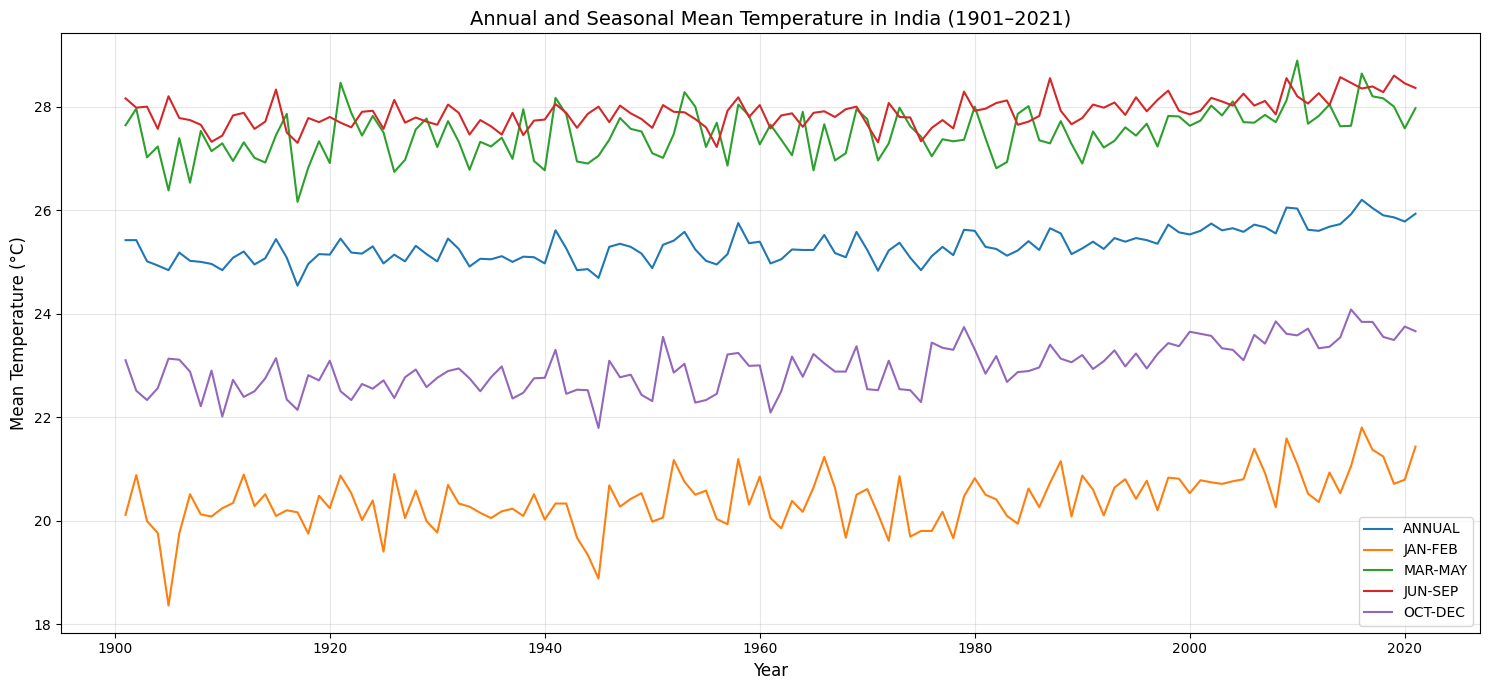

In [ ]:


import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

for col in temperature_columns:
    plt.plot(
        df['YEAR'],
        df[col],
        label=col,
        linewidth=1.5
    )

plt.xlabel("Year", fontsize=12)
plt.ylabel("Mean Temperature (°C)", fontsize=12)
plt.title(
    "Annual and Seasonal Mean Temperature in India (1901–2021)",
    fontsize=14
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


TEMPERATURE CORRELATION MATRIX


,ANNUAL,JAN-FEB,MAR-MAY,JUN-SEP,OCT-DEC
ANNUAL,1.000,0.764,0.725,0.772,0.800
JAN-FEB,0.764,1.000,0.539,0.428,0.448
MAR-MAY,0.725,0.539,1.000,0.316,0.318
JUN-SEP,0.772,0.428,0.316,1.000,0.651
OCT-DEC,0.800,0.448,0.318,0.651,1.000


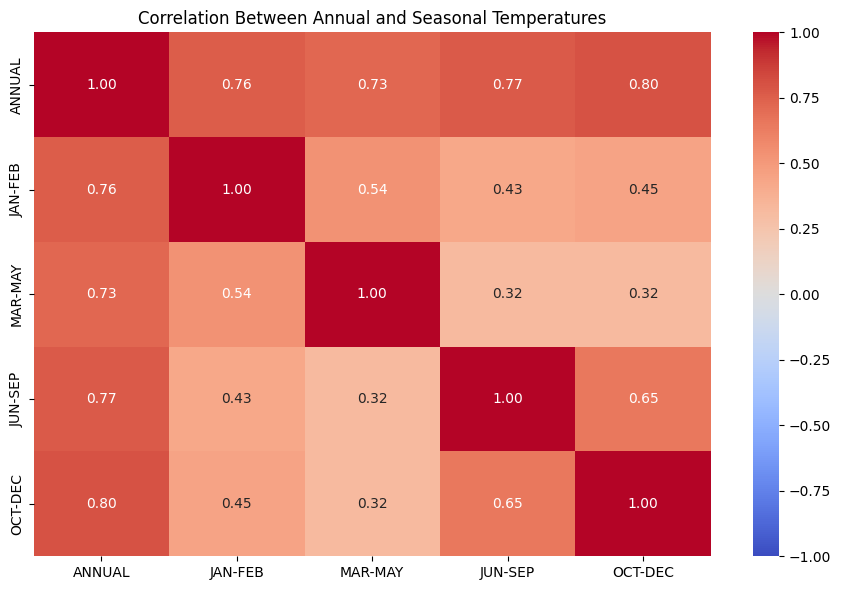

In [ ]:



correlation = df[temperature_columns].corr()

print("TEMPERATURE CORRELATION MATRIX")
display(correlation.round(3))

import seaborn as sns

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Annual and Seasonal Temperatures")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 3.1: Simple Linear Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import linregress
from sklearn.metrics import r2_score, mean_squared_error

temperature_columns = [
    'ANNUAL', 'JAN-FEB', 'MAR-MAY',
    'JUN-SEP', 'OCT-DEC'
]

X = df['YEAR'].values
results = []

for col in temperature_columns:

    y = df[col].values

    # Fit linear regression
    model = linregress(X, y)

    # Predicted temperatures
    y_pred = model.intercept + model.slope * X

    # Evaluation metrics
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))

    # Convert slope into °C per decade
    slope_per_decade = model.slope * 10

    results.append({
        'Temperature Series': col,
        'Slope (°C/year)': model.slope,
        'Warming Rate (°C/decade)': slope_per_decade,
        'R²': r2,
        'RMSE (°C)': rmse,
        'P-value': model.pvalue
    })

linear_results = pd.DataFrame(results)

print("LINEAR REGRESSION RESULTS")
display(linear_results.round(5))


LINEAR REGRESSION RESULTS


,Temperature Series,Slope (°C/year),Warming Rate (°C/decade),R²,RMSE (°C),P-value
0,ANNUAL,0.00628,0.06278,0.48421,0.22631,0.0
1,JAN-FEB,0.00705,0.07046,0.22595,0.45555,0.0
2,MAR-MAY,0.00572,0.05722,0.18603,0.41805,0.0
3,JUN-SEP,0.00431,0.04312,0.27947,0.24186,0.0
4,OCT-DEC,0.00896,0.08956,0.46495,0.33559,0.0


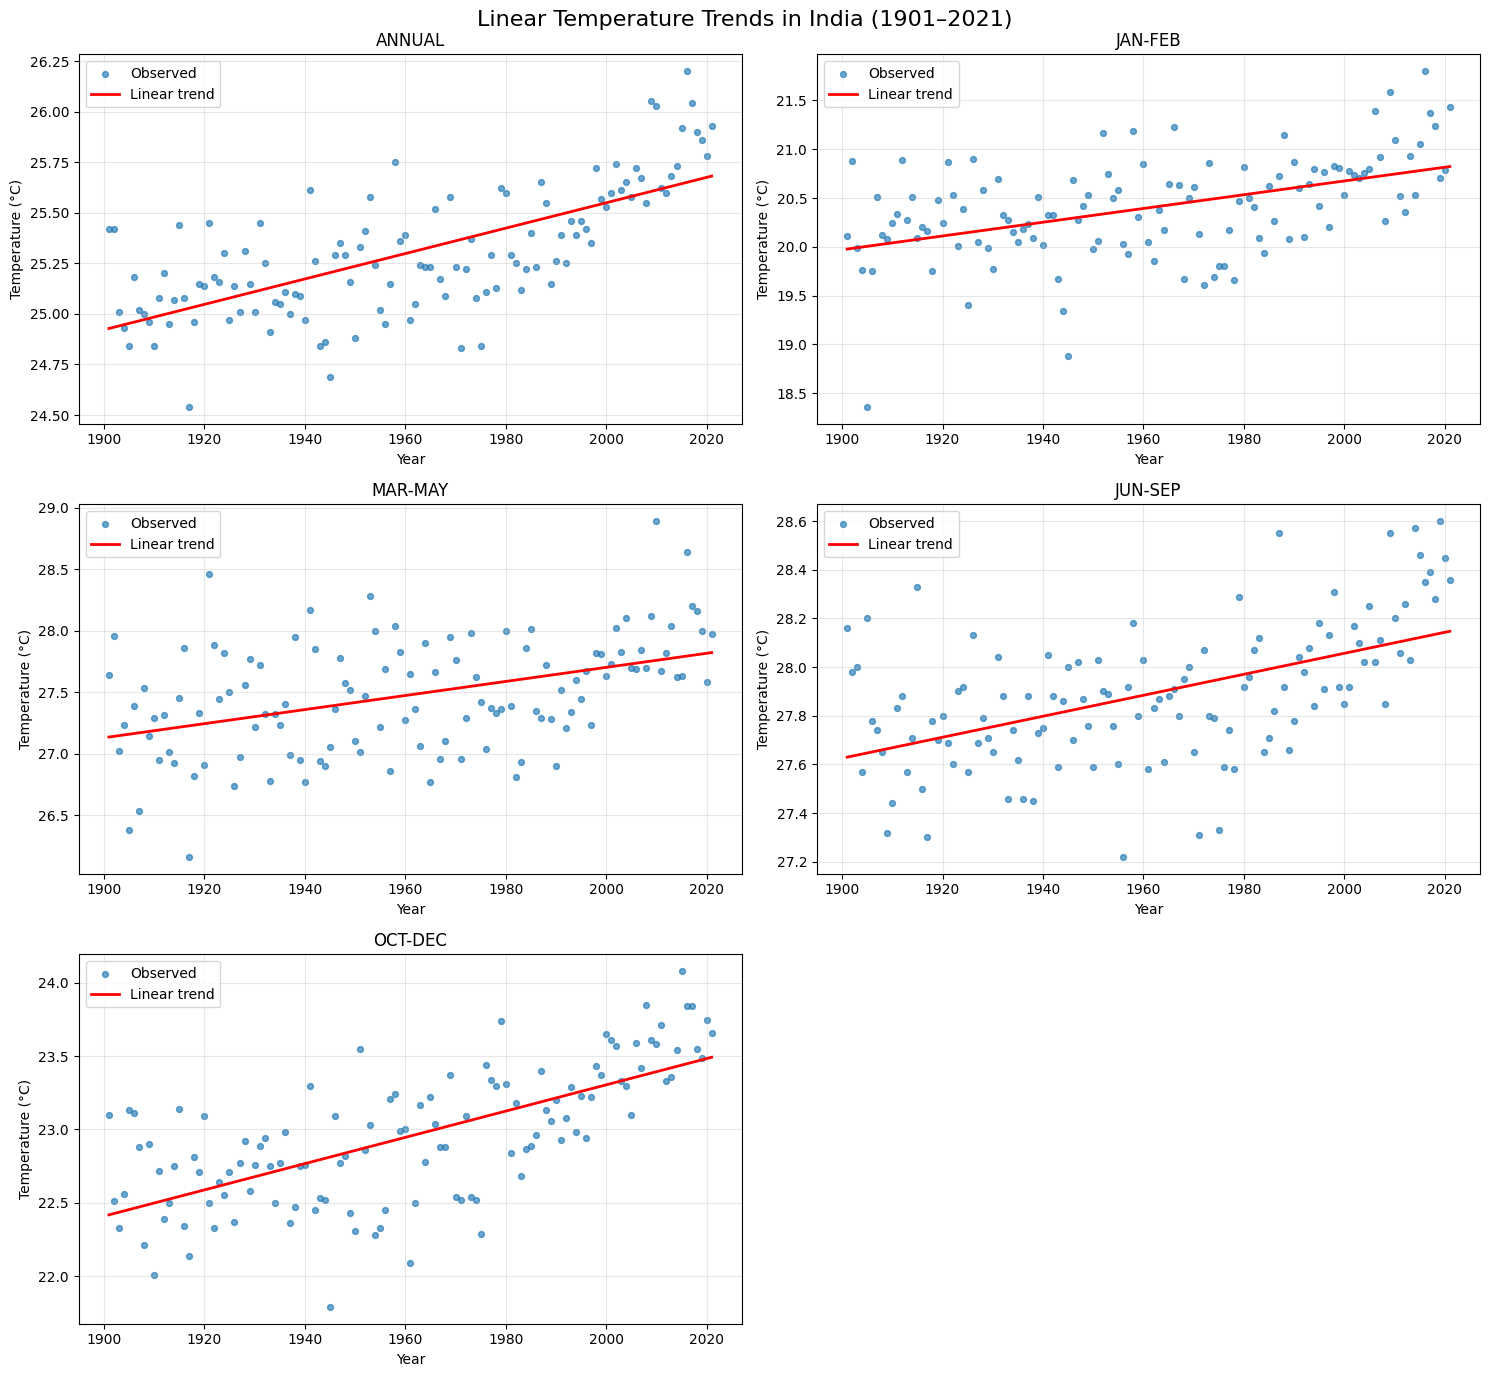

In [ ]:

# STEP 3.2: Plot Linear Regression Trends

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(temperature_columns):

    X = df['YEAR'].values
    y = df[col].values

    model = linregress(X, y)
    y_pred = model.intercept + model.slope * X

    axes[i].scatter(X, y, s=18, alpha=0.65, label='Observed')
    axes[i].plot(X, y_pred, color='red',
                 linewidth=2, label='Linear trend')

    axes[i].set_title(col)
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Temperature (°C)')
    axes[i].grid(alpha=0.3)
    axes[i].legend()

# Remove unused sixth plot
fig.delaxes(axes[5])

plt.suptitle(
    'Linear Temperature Trends in India (1901–2021)',
    fontsize=16
)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 4.1: Polynomial Regression

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

X = (df[['YEAR']].values - 1901) / 10

poly_results = []

for col in temperature_columns:

    y = df[col].values

    for degree in [2, 3, 4]:

        model = make_pipeline(
            PolynomialFeatures(degree=degree, include_bias=False),
            StandardScaler(),
            Ridge(alpha=0.01)
        )

        model.fit(X, y)
        y_pred = model.predict(X)

        poly_results.append({
            'Temperature Series': col,
            'Degree': degree,
            'R²': r2_score(y, y_pred),
            'RMSE (°C)': np.sqrt(mean_squared_error(y, y_pred))
        })

poly_results = pd.DataFrame(poly_results)

print("POLYNOMIAL REGRESSION RESULTS")
display(poly_results.round(5))


POLYNOMIAL REGRESSION RESULTS


,Temperature Series,Degree,R²,RMSE (°C)
0,ANNUAL,2,0.59093,0.20154
1,ANNUAL,3,0.60424,0.19823
2,ANNUAL,4,0.60548,0.19792
3,JAN-FEB,2,0.27101,0.44209
4,JAN-FEB,3,0.28964,0.43640
5,JAN-FEB,4,0.28976,0.43636
6,MAR-MAY,2,0.21017,0.41180
7,MAR-MAY,3,0.23068,0.40642
8,MAR-MAY,4,0.23218,0.40602
9,JUN-SEP,2,0.41015,0.21883


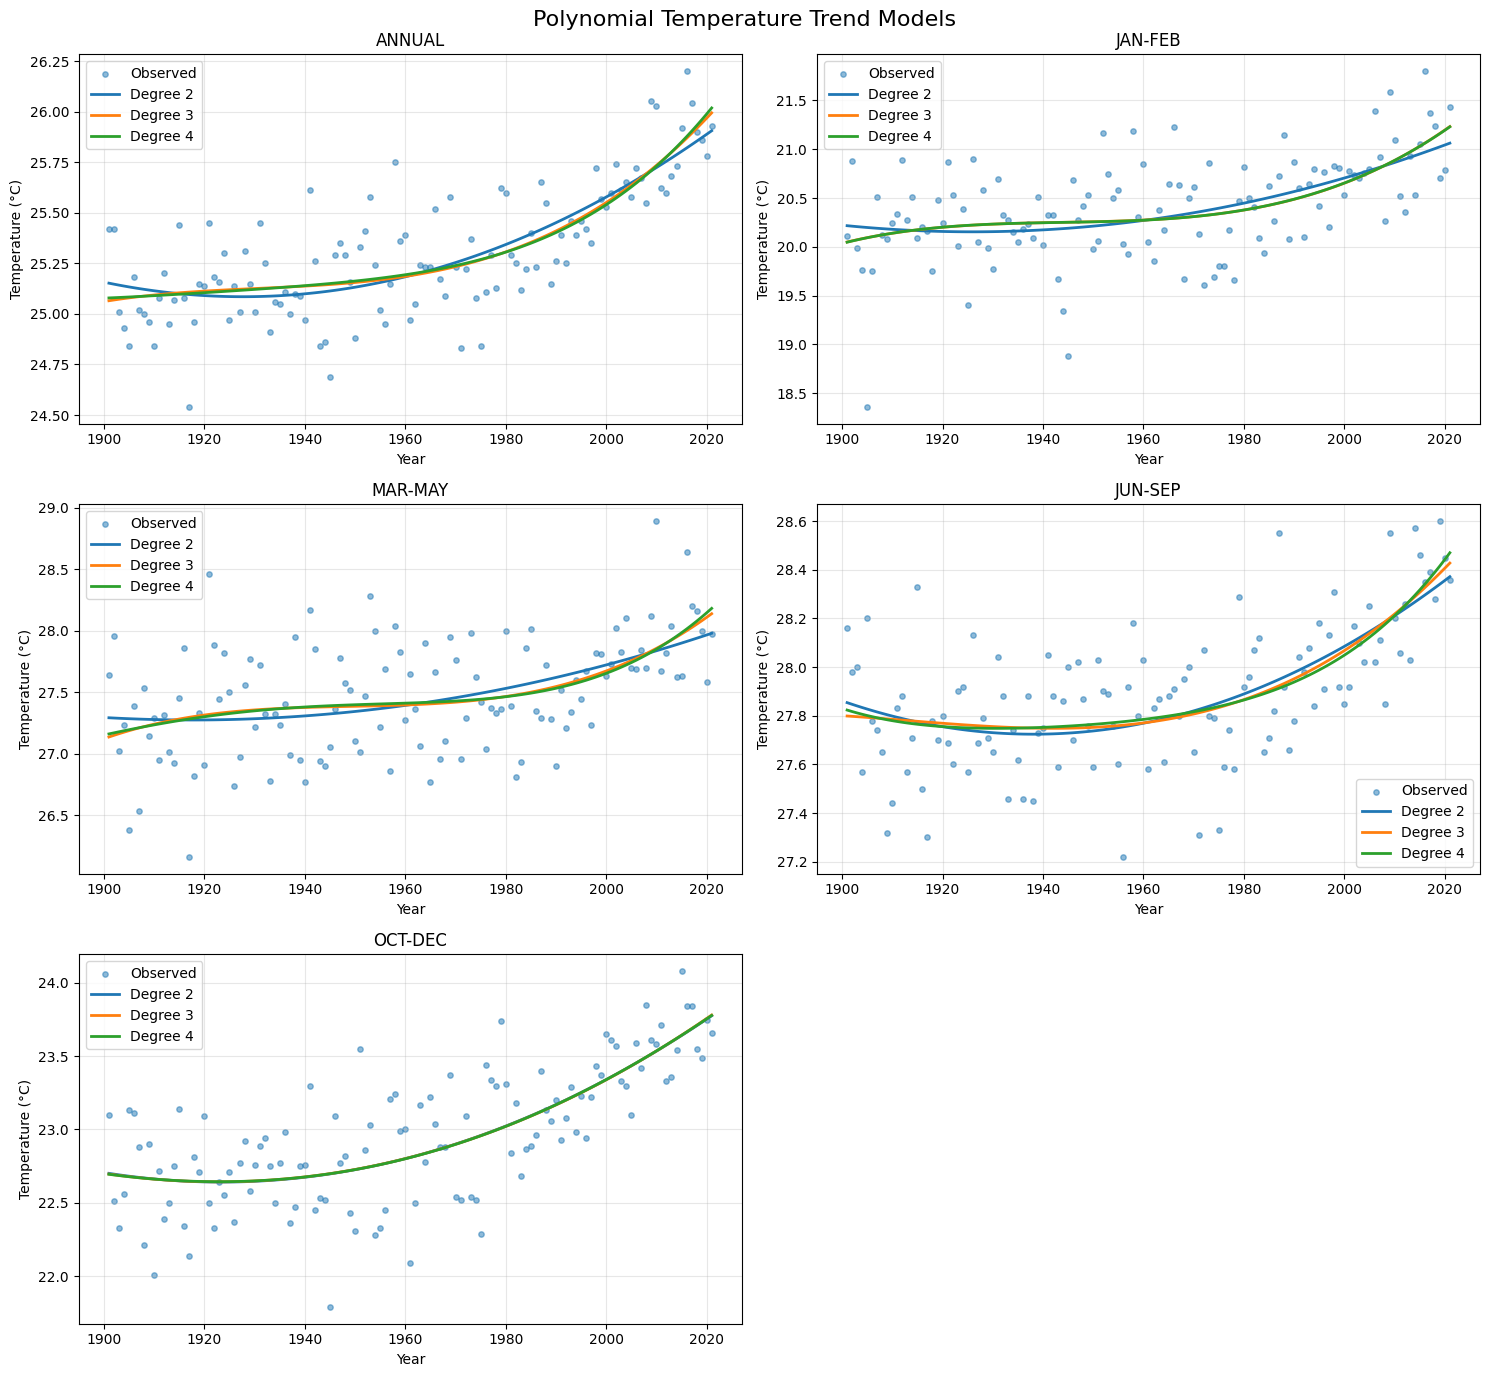

In [ ]:

# STEP 4.2: Polynomial Trend Graphs

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(temperature_columns):

    X = (df[['YEAR']].values - 1901) / 10
    y = df[col].values

    axes[i].scatter(df['YEAR'], y, s=15,
                    alpha=0.5, label='Observed')

    for degree in [2, 3, 4]:

        model = make_pipeline(
            PolynomialFeatures(degree=degree, include_bias=False),
            StandardScaler(),
            Ridge(alpha=0.01)
        )

        model.fit(X, y)
        y_pred = model.predict(X)

        axes[i].plot(
            df['YEAR'], y_pred,
            linewidth=2,
            label=f'Degree {degree}'
        )

    axes[i].set_title(col)
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Temperature (°C)')
    axes[i].grid(alpha=0.3)
    axes[i].legend()

fig.delaxes(axes[5])

plt.suptitle('Polynomial Temperature Trend Models',
             fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 4.3: Time Series Cross-Validation
# Select polynomial degree using future-year validation

import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge

# Center and scale year
X = ((df[['YEAR']] - 1901) / 10).values

# Five chronological validation splits
tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

for col in temperature_columns:

    y = df[col].values

    for degree in [1, 2, 3, 4]:

        model = make_pipeline(
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            ),
            StandardScaler(),
            Ridge(alpha=0.01)
        )

        scores = cross_validate(
            model,
            X,
            y,
            cv=tscv,
            scoring={
                'RMSE': 'neg_root_mean_squared_error',
                'R2': 'r2'
            }
        )

        cv_results.append({
            'Temperature Series': col,
            'Degree': degree,
            'Mean CV RMSE': -scores['test_RMSE'].mean(),
            'RMSE Std': scores['test_RMSE'].std(),
            'Mean CV R2': scores['test_R2'].mean()
        })

cv_results = pd.DataFrame(cv_results)

print("TIME SERIES CROSS-VALIDATION RESULTS")
display(cv_results.round(5))

# Select best degree based on lowest CV RMSE
best_models = (
    cv_results.loc[
        cv_results.groupby('Temperature Series')['Mean CV RMSE'].idxmin()
    ]
    .sort_values('Temperature Series')
    .reset_index(drop=True)
)

print("\nBEST POLYNOMIAL DEGREE FOR EACH SERIES")
display(best_models.round(5))


TIME SERIES CROSS-VALIDATION RESULTS


,Temperature Series,Degree,Mean CV RMSE,RMSE Std,Mean CV R2
0,ANNUAL,1,0.24914,0.07779,-0.84138
1,ANNUAL,2,0.46432,0.44717,-13.01404
2,ANNUAL,3,0.35905,0.17269,-3.02715
3,ANNUAL,4,0.98375,1.38604,-99.24710
4,JAN-FEB,1,0.51067,0.08014,-0.70752
5,JAN-FEB,2,0.65957,0.22995,-2.49648
6,JAN-FEB,3,1.22001,1.06432,-21.08747
7,JAN-FEB,4,1.88353,1.74150,-55.67306
8,MAR-MAY,1,0.41937,0.05899,-0.36135
9,MAR-MAY,2,0.90112,0.90972,-8.98321



BEST POLYNOMIAL DEGREE FOR EACH SERIES


,Temperature Series,Degree,Mean CV RMSE,RMSE Std,Mean CV R2
0,ANNUAL,1,0.24914,0.07779,-0.84138
1,JAN-FEB,1,0.51067,0.08014,-0.70752
2,JUN-SEP,1,0.29287,0.05284,-1.05937
3,MAR-MAY,1,0.41937,0.05899,-0.36135
4,OCT-DEC,1,0.36848,0.07278,-0.65454


In [ ]:

# STEP 4.4: Improved Time-Series Cross-Validation

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge

import numpy as np
import pandas as pd

X = ((df[['YEAR']] - 1901) / 10).values

# 5 folds, each with 10 validation years
tscv = TimeSeriesSplit(n_splits=5, test_size=10)

improved_results = []

for col in temperature_columns:

    y = df[col].values

    for degree in [1, 2, 3, 4]:

        model = make_pipeline(
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            ),
            StandardScaler(),
            Ridge(alpha=0.01)
        )

        scores = cross_validate(
            model,
            X,
            y,
            cv=tscv,
            scoring={
                'RMSE': 'neg_root_mean_squared_error',
                'R2': 'r2'
            }
        )

        improved_results.append({
            'Series': col,
            'Degree': degree,
            'CV RMSE': -scores['test_RMSE'].mean(),
            'CV R2': scores['test_R2'].mean()
        })

improved_results = pd.DataFrame(improved_results)

print("IMPROVED CROSS-VALIDATION RESULTS")
display(improved_results.round(5))

print("\nBEST DEGREE FOR EACH SERIES")

best_degree = improved_results.loc[
    improved_results.groupby('Series')['CV RMSE'].idxmin()
].reset_index(drop=True)

display(best_degree.round(5))


IMPROVED CROSS-VALIDATION RESULTS


,Series,Degree,CV RMSE,CV R2
0,ANNUAL,1,0.25308,-1.51033
1,ANNUAL,2,0.19062,-0.30378
2,ANNUAL,3,0.19128,-0.28286
3,ANNUAL,4,0.19157,-0.26193
4,JAN-FEB,1,0.45474,-0.46402
5,JAN-FEB,2,0.43497,-0.34450
6,JAN-FEB,3,0.43897,-0.33733
7,JAN-FEB,4,0.45344,-0.46214
8,MAR-MAY,1,0.37227,-0.42569
9,MAR-MAY,2,0.37804,-0.53656



BEST DEGREE FOR EACH SERIES


,Series,Degree,CV RMSE,CV R2
0,ANNUAL,2,0.19062,-0.30378
1,JAN-FEB,2,0.43497,-0.34450
2,JUN-SEP,2,0.21705,-0.23461
3,MAR-MAY,1,0.37227,-0.42569
4,OCT-DEC,2,0.26186,-0.05744


In [ ]:

# STEP 5.1: Ridge Regression - Alpha Tuning

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Best polynomial degrees selected from previous CV
selected_degrees = {
    'ANNUAL': 2,
    'JAN-FEB': 2,
    'MAR-MAY': 1,
    'JUN-SEP': 2,
    'OCT-DEC': 2
}

# Different regularisation strengths
alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

X = ((df[['YEAR']] - 1901) / 10).values

tscv = TimeSeriesSplit(n_splits=5, test_size=10)

ridge_results = []

for col in temperature_columns:

    y = df[col].values
    degree = selected_degrees[col]

    for alpha in alpha_values:

        model = make_pipeline(
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            ),
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        scores = cross_validate(
            model,
            X,
            y,
            cv=tscv,
            scoring={
                'RMSE': 'neg_root_mean_squared_error',
                'R2': 'r2'
            }
        )

        ridge_results.append({
            'Series': col,
            'Degree': degree,
            'Alpha': alpha,
            'CV RMSE': -scores['test_RMSE'].mean(),
            'CV R2': scores['test_R2'].mean()
        })

ridge_results = pd.DataFrame(ridge_results)

print("RIDGE REGRESSION RESULTS")
display(ridge_results.round(5))

# Select alpha with lowest CV RMSE
best_ridge = ridge_results.loc[
    ridge_results.groupby('Series')['CV RMSE'].idxmin()
].reset_index(drop=True)

print("\nBEST RIDGE MODEL FOR EACH SERIES")
display(best_ridge.round(5))


RIDGE REGRESSION RESULTS


,Series,Degree,Alpha,CV RMSE,CV R2
0,ANNUAL,2,0.001,0.19055,-0.30264
1,ANNUAL,2,0.010,0.19062,-0.30378
2,ANNUAL,2,0.100,0.19136,-0.31508
3,ANNUAL,2,1.000,0.19764,-0.41330
4,ANNUAL,2,10.000,0.22120,-0.82812
5,ANNUAL,2,100.000,0.27402,-2.00807
6,JAN-FEB,2,0.001,0.43500,-0.34471
7,JAN-FEB,2,0.010,0.43497,-0.34450
8,JAN-FEB,2,0.100,0.43477,-0.34260
9,JAN-FEB,2,1.000,0.43388,-0.33279



BEST RIDGE MODEL FOR EACH SERIES


,Series,Degree,Alpha,CV RMSE,CV R2
0,ANNUAL,2,0.001,0.19055,-0.30264
1,JAN-FEB,2,1.000,0.43388,-0.33279
2,JUN-SEP,2,0.001,0.21696,-0.23322
3,MAR-MAY,1,0.001,0.37227,-0.42565
4,OCT-DEC,2,1.000,0.26132,-0.02008


In [ ]:

# STEP 6.1: Piecewise Linear Regression
# Compare historical and recent warming rates

import numpy as np
import pandas as pd
import statsmodels.api as sm

break_year = 1981

# Time measured in decades from 1901
df['TIME_DECADE'] = (df['YEAR'] - 1901) / 10

# Continuous slope-change variable
df['POST_1981'] = np.maximum(
    df['YEAR'] - break_year, 0
) / 10

acceleration_results = []

for col in temperature_columns:

    y = df[col]

    # Continuous piecewise model
    X = df[['TIME_DECADE', 'POST_1981']]
    X = sm.add_constant(X)

    # HAC standard errors account for autocorrelation
    model = sm.OLS(y, X).fit(
        cov_type='HAC',
        cov_kwds={'maxlags': 5}
    )

    # Early-period slope (°C/decade)
    early_slope = model.params['TIME_DECADE']

    # Change in slope after 1981
    slope_change = model.params['POST_1981']

    # Recent-period slope (°C/decade)
    recent_slope = early_slope + slope_change

    # Statistical test of slope change
    p_value = model.pvalues['POST_1981']

    ci = model.conf_int().loc['POST_1981']

    acceleration_results.append({
        'Series': col,
        'Early Slope (°C/decade)': early_slope,
        'Recent Slope (°C/decade)': recent_slope,
        'Slope Change': slope_change,
        'Slope Change p-value': p_value,
        'Change CI Lower': ci[0],
        'Change CI Upper': ci[1],
        'R²': model.rsquared
    })

acceleration_results = pd.DataFrame(acceleration_results)

print("WARMING RATE COMPARISON: 1901-1980 vs 1981-2021")
display(acceleration_results.round(5))


WARMING RATE COMPARISON: 1901-1980 vs 1981-2021


,Series,Early Slope (°C/decade),Recent Slope (°C/decade),Slope Change,Slope Change p-value,Change CI Lower,Change CI Upper,R²
0,ANNUAL,0.02332,0.17444,0.15112,0.00000,0.11200,0.19023,0.60816
1,JAN-FEB,0.02315,0.20438,0.18123,0.00028,0.08349,0.27897,0.29197
2,MAR-MAY,0.02212,0.15655,0.13443,0.00010,0.06692,0.20194,0.23139
3,JUN-SEP,0.00652,0.14672,0.14019,0.00000,0.08838,0.19201,0.40994
4,OCT-DEC,0.04700,0.21003,0.16303,0.00004,0.08551,0.24055,0.53300


In [ ]:

# STEP 6.4: Breakpoint Sensitivity Analysis

import numpy as np
import pandas as pd
import statsmodels.api as sm

breakpoints = [1971, 1981, 1991]

sensitivity_results = []

for breakpoint in breakpoints:

    for col in temperature_columns:

        y = df[col]

        # Time measured in decades
        time_decade = (df['YEAR'] - 1901) / 10

        # Slope-change variable
        post_break = np.maximum(
            df['YEAR'] - breakpoint, 0
        ) / 10

        X = pd.DataFrame({
            'TIME_DECADE': time_decade,
            'POST_BREAK': post_break
        })

        X = sm.add_constant(X)

        model = sm.OLS(y, X).fit(
            cov_type='HAC',
            cov_kwds={'maxlags': 5}
        )

        early_slope = model.params['TIME_DECADE']
        slope_change = model.params['POST_BREAK']
        recent_slope = early_slope + slope_change

        sensitivity_results.append({
            'Breakpoint': breakpoint,
            'Series': col,
            'Early Slope': early_slope,
            'Recent Slope': recent_slope,
            'Slope Change': slope_change,
            'P-value': model.pvalues['POST_BREAK']
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("BREAKPOINT SENSITIVITY RESULTS")
display(sensitivity_df.round(6))


BREAKPOINT SENSITIVITY RESULTS


,Breakpoint,Series,Early Slope,Recent Slope,Slope Change,P-value
0,1971,ANNUAL,0.014899,0.141845,0.126947,0.000000
1,1971,JAN-FEB,0.014958,0.162131,0.147173,0.004426
2,1971,MAR-MAY,0.020730,0.117478,0.096748,0.004822
3,1971,JUN-SEP,-0.003235,0.119687,0.122922,0.000000
4,1971,OCT-DEC,0.032910,0.183125,0.150215,0.000001
5,1981,ANNUAL,0.023323,0.174443,0.151119,0.000000
6,1981,JAN-FEB,0.023150,0.204379,0.181229,0.000279
7,1981,MAR-MAY,0.022122,0.156553,0.134431,0.000095
8,1981,JUN-SEP,0.006524,0.146716,0.140192,0.000000
9,1981,OCT-DEC,0.047001,0.210028,0.163027,0.000038


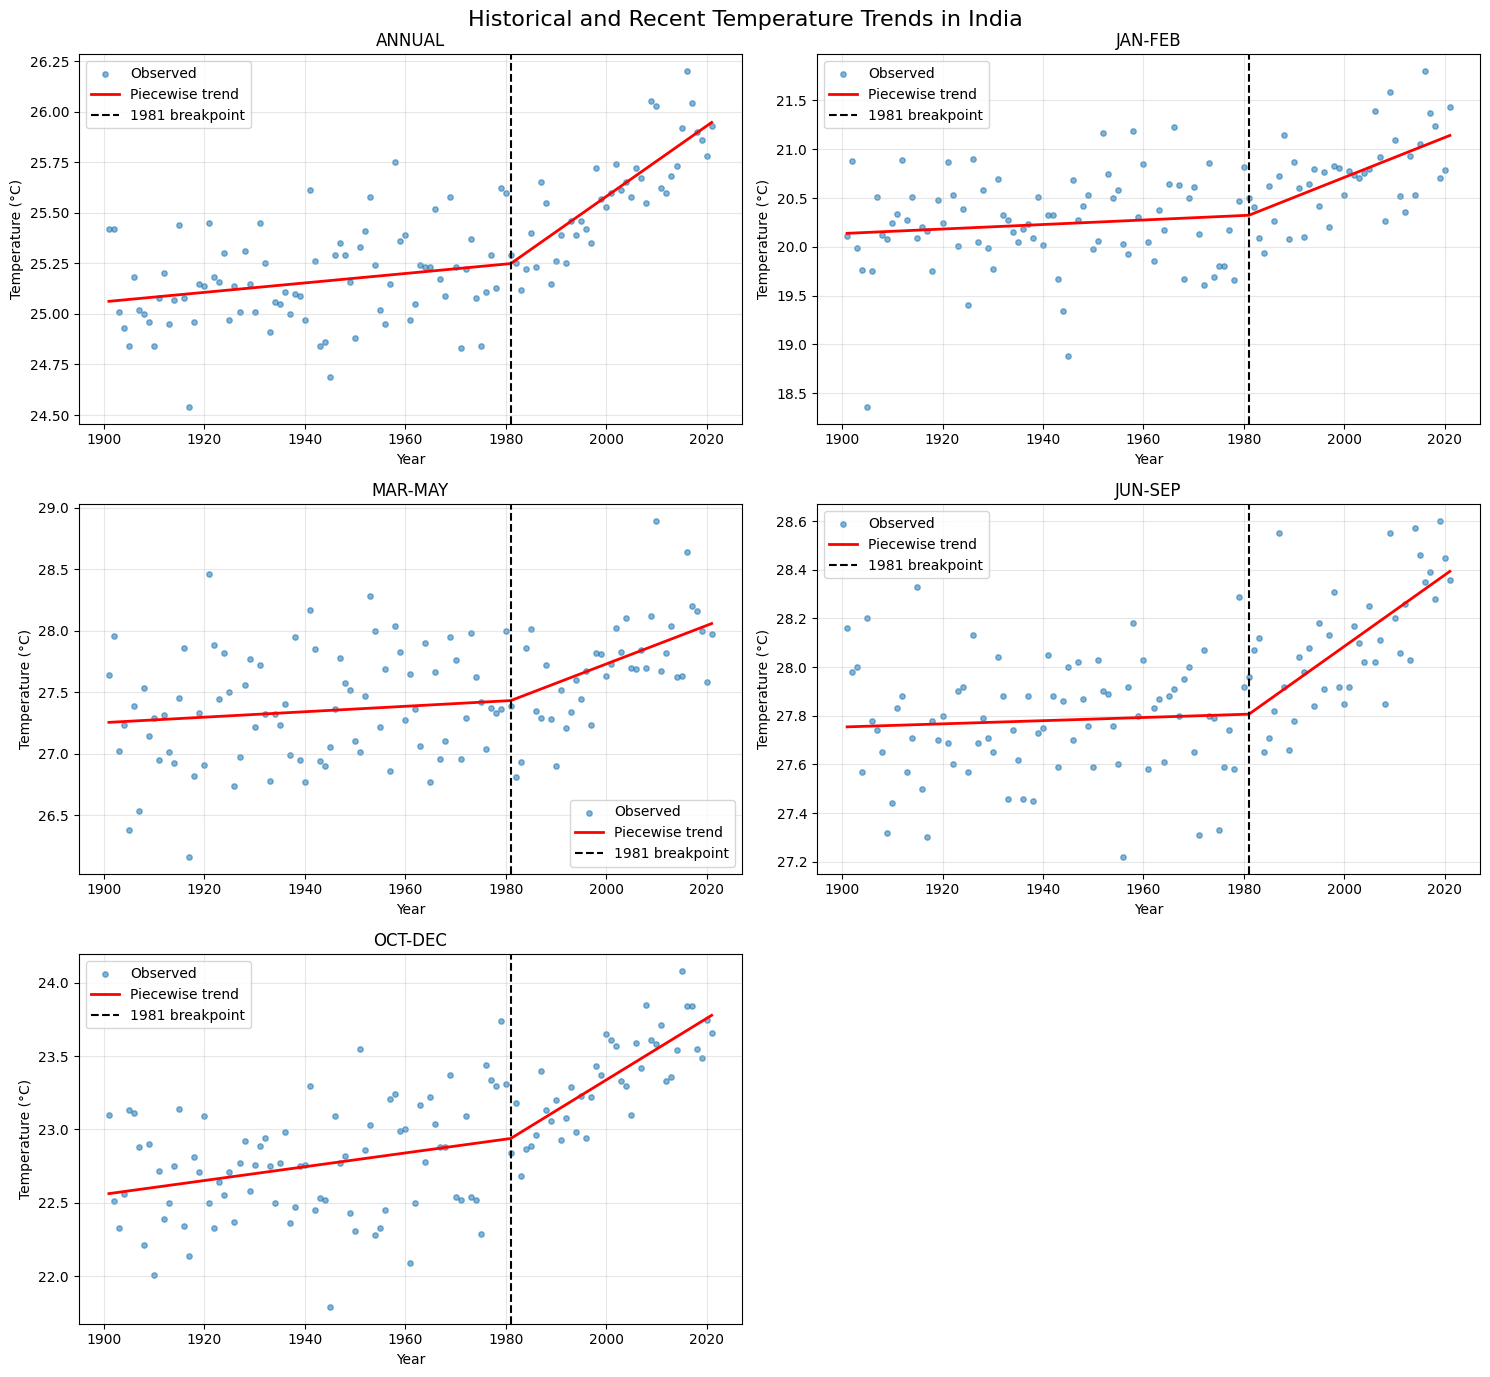

In [ ]:

# STEP 6.5: Piecewise Trend Visualisation

import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm

breakpoint = 1981

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(temperature_columns):

    time_decade = (df['YEAR'] - 1901) / 10

    post_break = np.maximum(
        df['YEAR'] - breakpoint, 0
    ) / 10

    X = pd.DataFrame({
        'TIME_DECADE': time_decade,
        'POST_BREAK': post_break
    })

    X = sm.add_constant(X)

    model = sm.OLS(df[col], X).fit()

    predicted = model.predict(X)

    axes[i].scatter(
        df['YEAR'], df[col],
        s=15, alpha=0.55, label='Observed'
    )

    axes[i].plot(
        df['YEAR'], predicted,
        color='red', linewidth=2,
        label='Piecewise trend'
    )

    axes[i].axvline(
        breakpoint,
        color='black',
        linestyle='--',
        label='1981 breakpoint'
    )

    axes[i].set_title(col)
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Temperature (°C)')
    axes[i].grid(alpha=0.3)
    axes[i].legend()

fig.delaxes(axes[5])

plt.suptitle(
    'Historical and Recent Temperature Trends in India',
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

# STEP 7.1: Residual Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox

breakpoint = 1981

residual_results = []
residual_store = {}

for col in temperature_columns:

    y = df[col].values

    time_decade = (df['YEAR'] - 1901) / 10

    post_break = np.maximum(
        df['YEAR'] - breakpoint, 0
    ) / 10

    X = pd.DataFrame({
        'TIME_DECADE': time_decade,
        'POST_BREAK': post_break
    })

    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    # Calculate residuals
    predicted = model.predict(X)
    residuals = y - predicted

    residual_store[col] = residuals

    # Durbin-Watson statistic
    dw = durbin_watson(residuals)

    # Ljung-Box autocorrelation test
    lb = acorr_ljungbox(
        residuals,
        lags=[5, 10],
        return_df=True
    )

    residual_results.append({
        'Series': col,
        'Residual Mean': np.mean(residuals),
        'Residual Std': np.std(residuals, ddof=1),
        'Durbin-Watson': dw,
        'Ljung-Box p (lag 5)': lb.loc[5, 'lb_pvalue'],
        'Ljung-Box p (lag 10)': lb.loc[10, 'lb_pvalue']
    })

residual_results = pd.DataFrame(residual_results)

print("RESIDUAL DIAGNOSTICS")
display(residual_results.round(5))


RESIDUAL DIAGNOSTICS


,Series,Residual Mean,Residual Std,Durbin-Watson,Ljung-Box p (lag 5),Ljung-Box p (lag 10)
0,ANNUAL,0.0,0.19807,1.58219,0.00029,0.00018
1,JAN-FEB,0.0,0.43750,1.84392,0.52627,0.63819
2,MAR-MAY,0.0,0.40792,1.96391,0.37196,0.19477
3,JUN-SEP,-0.0,0.21978,1.98534,0.69574,0.78485
4,OCT-DEC,0.0,0.31482,1.77224,0.02615,0.21377


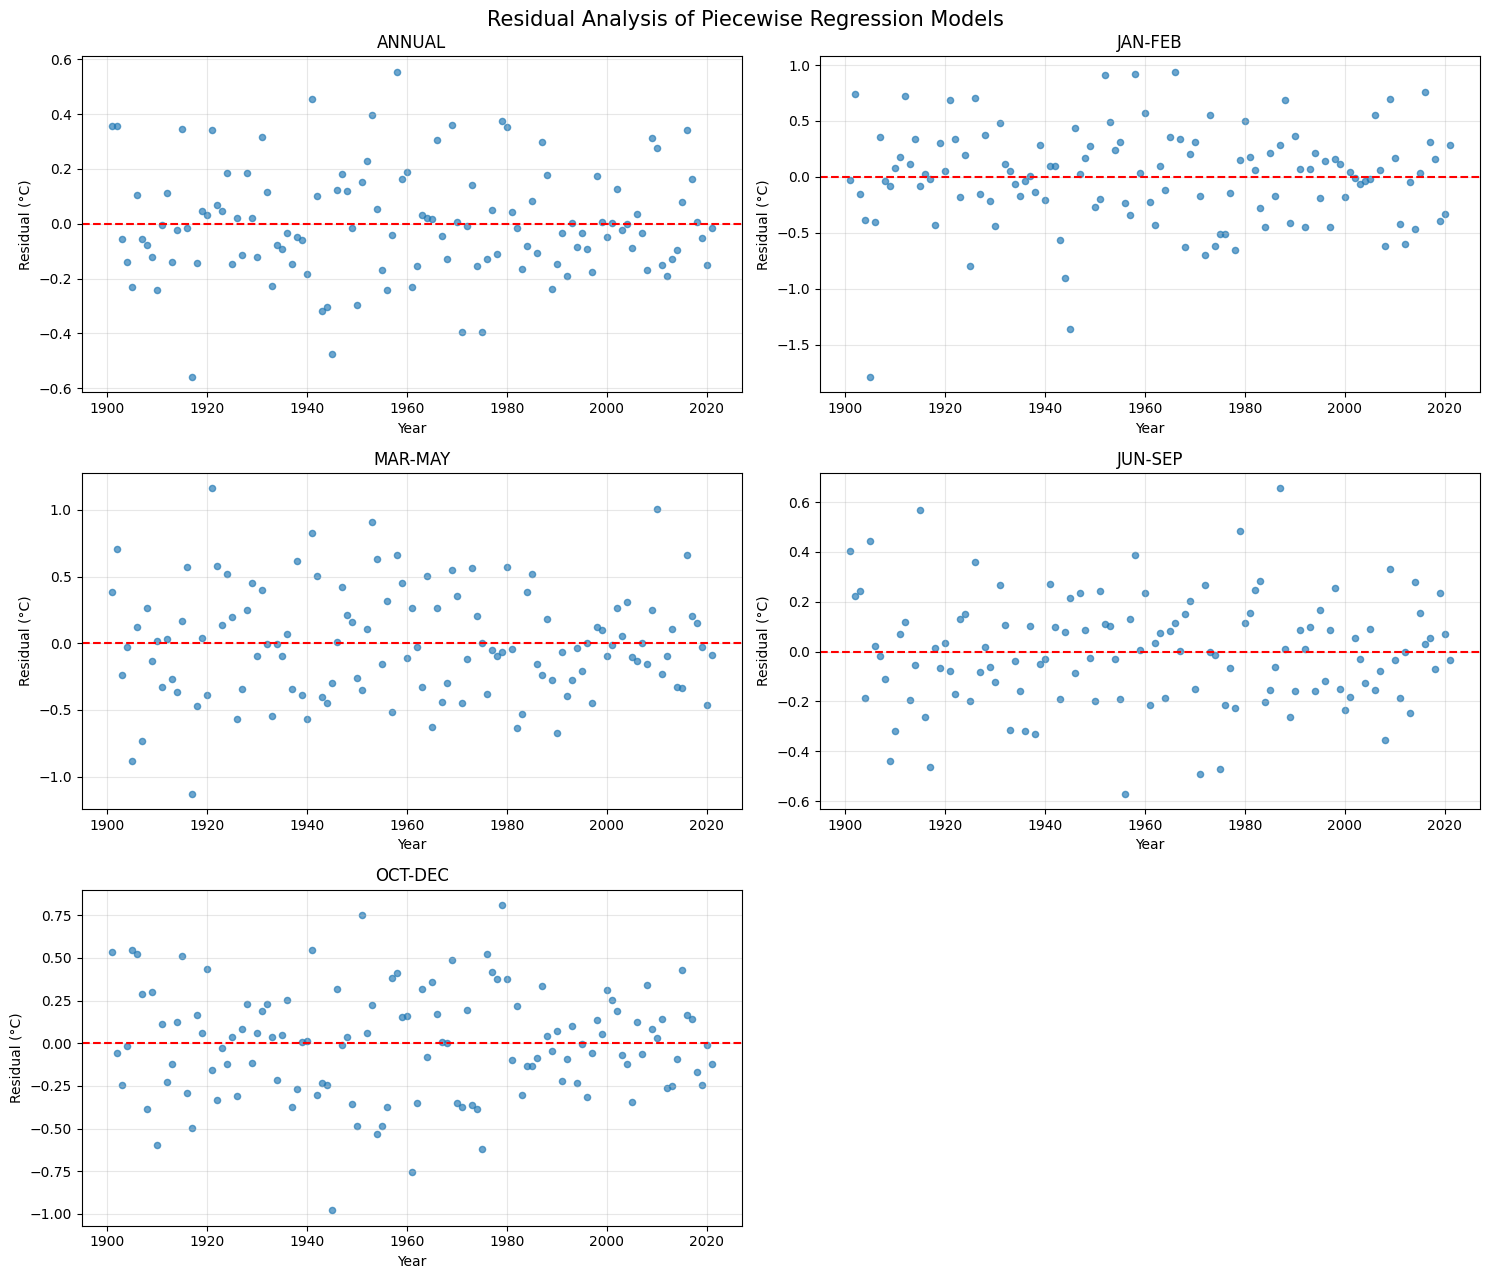

In [ ]:

# STEP 7.2: Residuals vs Year

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for i, col in enumerate(temperature_columns):

    residuals = residual_store[col]

    axes[i].scatter(
        df['YEAR'],
        residuals,
        alpha=0.65,
        s=20
    )

    axes[i].axhline(
        0,
        color='red',
        linestyle='--'
    )

    axes[i].set_title(col)
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Residual (°C)')
    axes[i].grid(alpha=0.3)

fig.delaxes(axes[5])

plt.suptitle(
    'Residual Analysis of Piecewise Regression Models',
    fontsize=15
)

plt.tight_layout()
plt.show()


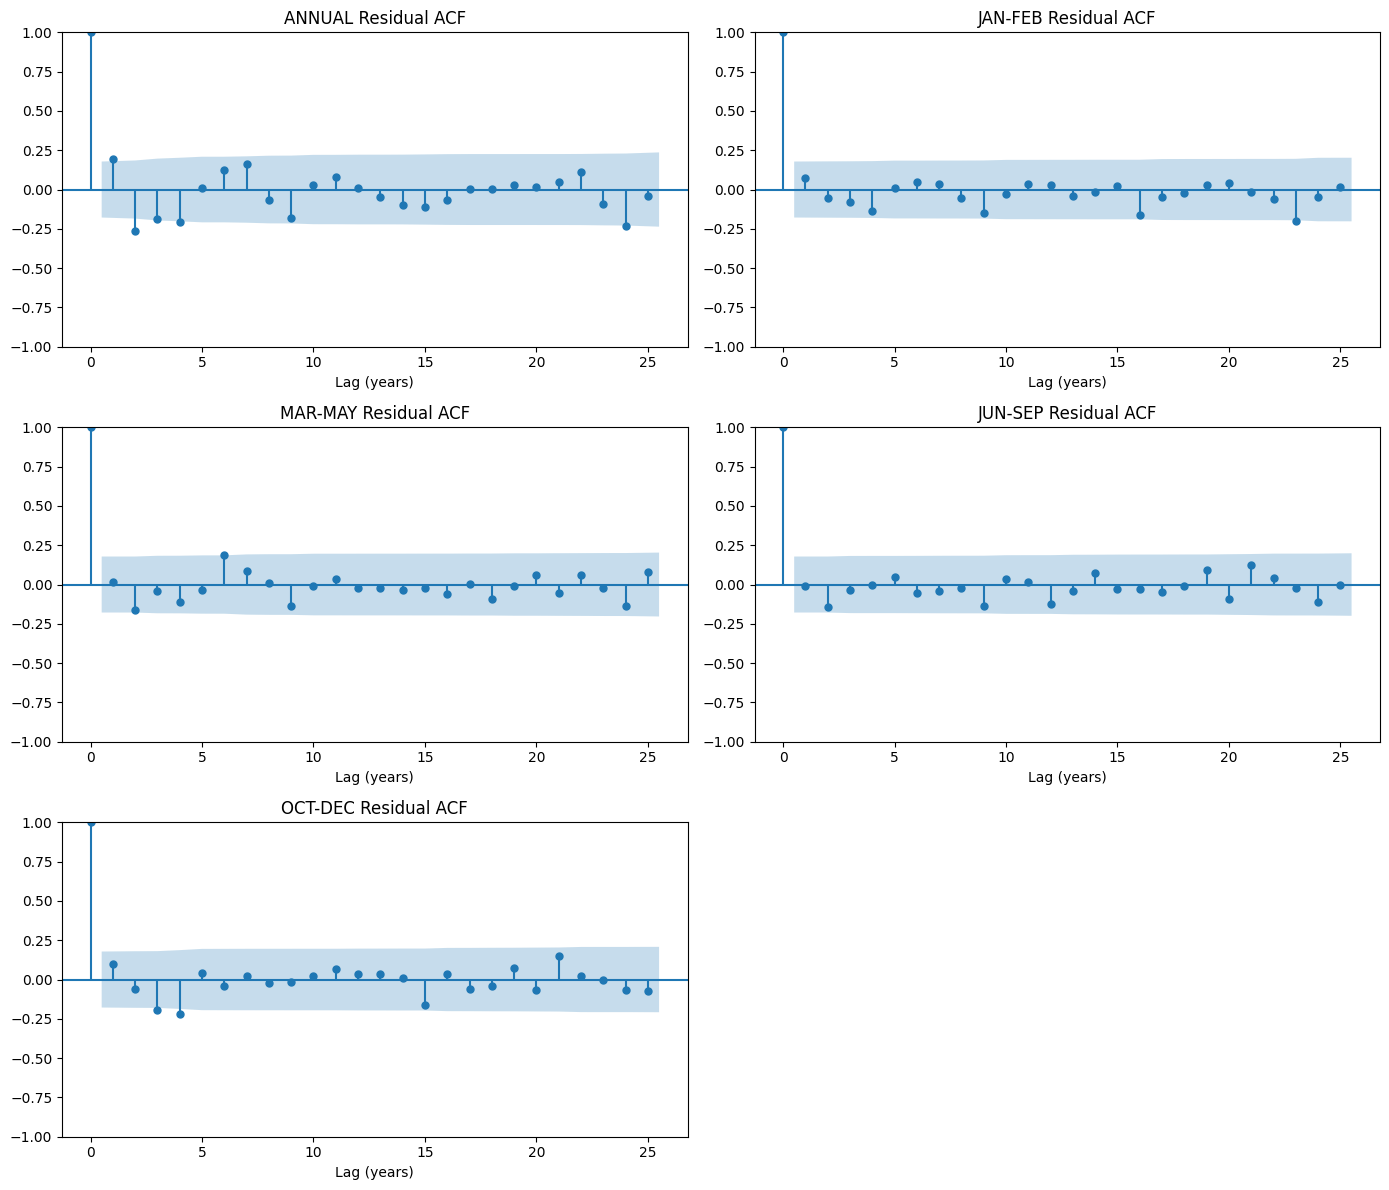

In [ ]:

# STEP 7.3: Residual Autocorrelation

from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(temperature_columns):

    plot_acf(
        residual_store[col],
        lags=25,
        ax=axes[i],
        alpha=0.05
    )

    axes[i].set_title(f'{col} Residual ACF')
    axes[i].set_xlabel('Lag (years)')

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


In [ ]:

# STEP 8: Full-period warming trends (1901-2021)

import numpy as np
import pandas as pd
import statsmodels.api as sm

trend_results = []

for col in temperature_columns:

    # Time in decades from 1901
    X = (df['YEAR'] - 1901) / 10
    X = sm.add_constant(X)

    model = sm.OLS(df[col], X).fit(
        cov_type='HAC',
        cov_kwds={'maxlags': 5}
    )

    slope = model.params.iloc[1]
    ci = model.conf_int().iloc[1]

    trend_results.append({
        'Series': col,
        'Trend (°C/decade)': slope,
        'Trend (°C/century)': slope * 10,
        '95% CI Lower (°C/century)': ci.iloc[0] * 10,
        '95% CI Upper (°C/century)': ci.iloc[1] * 10,
        'HAC p-value': model.pvalues.iloc[1],
        'R²': model.rsquared
    })

full_period_trends = pd.DataFrame(trend_results)

print("FULL-PERIOD LINEAR WARMING TRENDS (1901-2021)")
display(full_period_trends.round(5))


FULL-PERIOD LINEAR WARMING TRENDS (1901-2021)


,Series,Trend (°C/decade),Trend (°C/century),95% CI Lower (°C/century),95% CI Upper (°C/century),HAC p-value,R²
0,ANNUAL,0.06278,0.62777,0.44934,0.80619,0.00000,0.48421
1,JAN-FEB,0.07046,0.70465,0.43883,0.97046,0.00000,0.22595
2,MAR-MAY,0.05722,0.57219,0.34704,0.79733,0.00000,0.18603
3,JUN-SEP,0.04312,0.43125,0.24050,0.62200,0.00001,0.27947
4,OCT-DEC,0.08956,0.89564,0.67820,1.11307,0.00000,0.46495
